# 🕸️ Sesión 1: El ADN de las Redes
Representación de Grafos: Matriz vs Lista de Adyacencia.

## 📐 Formalización Matemática: ¿Qué es un Grafo?

Un grafo es una estructura matemática que modela relaciones entre objetos. Formalmente se define como un par ordenado:

$$G = (V, E)$$

Donde:
*   **$V$ (Vértices / Nodos):** Es el conjunto de entidades que conforman la red. En nuestro ejemplo del pizarrón, $V = \{\text{Ana, Carlos, Luis, Beti}\}$.
*   **$E$ (Aristas / Edges):** Es el conjunto de conexiones (pares de vértices). Si Ana sigue a Carlos, existe una arista $e = (Ana, Carlos)$.

---
### Tipos de Relaciones

1.  **Grafo Dirigido (DiGraph):** Las aristas tienen dirección (flechas). Si $(u, v) \in E$, no implica necesariamente que $(v, u) \in E$. *(Ejemplo: Seguir a alguien en Instagram, transferencias bancarias).* 
2.  **Grafo No Dirigido (Graph):** Las relaciones son recíprocas. La arista $(u, v)$ es idéntica a $(v, u)$. *(Ejemplo: Ser amigos en Facebook, conexiones Bluetooth).* 
3.  **Grafo Ponderado (Weighted Graph):** Cada arista tiene un peso o costo numérico $w(u,v)$. *(Ejemplo: La distancia en kilómetros entre dos aeropuertos, la cantidad de mensajes entre dos usuarios).*

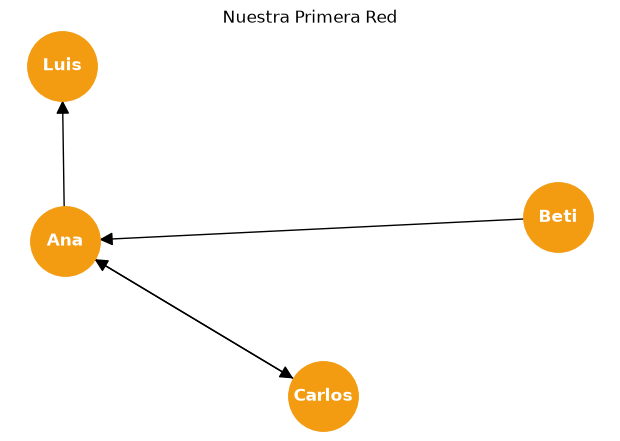

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.DiGraph()
G.add_edges_from([('Ana', 'Carlos'), ('Carlos', 'Ana'), ('Ana', 'Luis'), ('Beti', 'Ana')])

# 2. Dibujar el Grafo
plt.figure(figsize=(6,4))
nx.draw(G, with_labels=True, node_color='#F39C12', node_size=2500, font_weight='bold', font_color='white', arrowsize=20)
plt.title('Nuestra Primera Red')
plt.show()

### ⚠️ El colapso en la RAM: La Matriz de Adyacencia
Fácil de leer para las matemáticas, terrible para la memoria de la computadora en Big Data.

In [2]:
matriz = nx.adjacency_matrix(G).todense()
print("Nodos en orden:", G.nodes())
print("\nMatriz de Adyacencia:")
print(matriz)

Nodos en orden: ['Ana', 'Carlos', 'Luis', 'Beti']

Matriz de Adyacencia:
[[0 1 1 0]
 [1 0 0 0]
 [0 0 0 0]
 [1 0 0 0]]


### 🚀 La Salvación: Lista de Aristas (Edge List)
Solo guardamos las conexiones que SÍ existen.

In [3]:
print("Lista de Aristas (Edge List):")
for edge in G.edges():
    print(f"{edge[0]} ---> {edge[1]}")

Lista de Aristas (Edge List):
Ana ---> Carlos
Ana ---> Luis
Carlos ---> Ana
Beti ---> Ana


---
# Práctica: Red de Vuelos

In [2]:
import pandas as pd

df_vuelos = pd.read_csv('vuelos_10k.csv')
print("Registros Iniciales: ", len(df_vuelos))
display(df_vuelos.head())

Registros Iniciales:  10000


,Origen,Destino,Distancia_km
0,RYI,KXK,965.34
1,ULE,PVC,1098.58
2,LTV,MOV,2713.63
3,NFR,CLR,1138.99
4,TSF,CZE,1691.08


## Fase 1: Limpieza Estructural (Data Cleaning)

In [3]:
print("Nulos por columna: ")
print(df_vuelos.isna().sum())

df_vuelos = df_vuelos.dropna(subset=['Origen', 'Destino']).copy()
print(f"\nEliminados: {len(df_vuelos)}")

Nulos por columna: 
Origen           51
Destino         100
Distancia_km      0
dtype: int64

Eliminados: 9849


In [4]:
minusculas = (~df_vuelos['Origen'].str.isupper() | ~df_vuelos['Destino'].str.isupper()).sum()
print("\nFilas con minusculas: ", minusculas)
df_vuelos['Origen'] = df_vuelos['Origen'].str.strip().str.upper()
df_vuelos['Destino'] = df_vuelos['Destino'].str.strip().str.upper()


Filas con minusculas:  800


In [5]:
self_loops = (df_vuelos['Origen'] == df_vuelos['Destino']).sum()
print(f"Self-loops encontrados: {self_loops}")
df_vuelos = df_vuelos[df_vuelos['Origen'] != df_vuelos['Destino']]

negativos = (df_vuelos['Distancia_km'] < 0).sum()
print(f"Distancias negativas: {negativos}")
df_vuelos['Distancia_km'] = df_vuelos['Distancia_km'].abs()

Self-loops encontrados: 105
Distancias negativas: 100


In [6]:
duplicados = df_vuelos.duplicated(subset=['Origen', 'Destino']).sum()
print(f"Rutas duplicadas: {duplicados}")
df_vuelos = df_vuelos.drop_duplicates(subset=['Origen', 'Destino']).reset_index(drop=True)

print("\nRegistros finales limpios: ", len(df_vuelos))
display(df_vuelos.describe())

Rutas duplicadas: 1

Registros finales limpios:  9743


,Distancia_km
count,9743.000000
mean,1516.650683
std,763.619223
min,0.040000
25%,964.520000
50%,1496.380000
75%,2034.255000
max,4818.320000


## Fase 2: Extracción de la Red

In [9]:
import networkx as nx

G = nx.from_pandas_edgelist(
    df_vuelos,
    source='Origen',
    target='Destino',
    edge_attr='Distancia_km',
    create_using=nx.DiGraph()
)

print("\nNodos (Aeropuertos):", G.number_of_nodes())
print("Aristas (Rutas):", G.number_of_edges())


Nodos (Aeropuertos): 3253
Aristas (Rutas): 9743


### Fase 3: El Experimento de la Memoria RAM

In [10]:
matriz_densa = nx.adjacency_matrix(G).todense()
print("Dimensiones de la matriz:", matriz_densa.shape)
print(f"Celdas en cero: {(matriz_densa == 0).mean() * 100:.2f}%")

mb_matriz = matriz_densa.nbytes / (1024 ** 2)
print(f"\nRAM Matriz de Adyacencia: {mb_matriz:.2f} MB")

mb_lista = df_vuelos.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"RAM Lista de Aristas: {mb_lista:.2f} MB")

veces = mb_matriz / mb_lista
print(f"\nLa matriz es {veces:.2f} veces más pesada que la lista de aristas.")

Dimensiones de la matriz: (3253, 3253)
Celdas en cero: 99.91%

RAM Matriz de Adyacencia: 80.73 MB
RAM Lista de Aristas: 1.04 MB

La matriz es 77.57 veces más pesada que la lista de aristas.


Hub principal: BLZ con 16 rutas


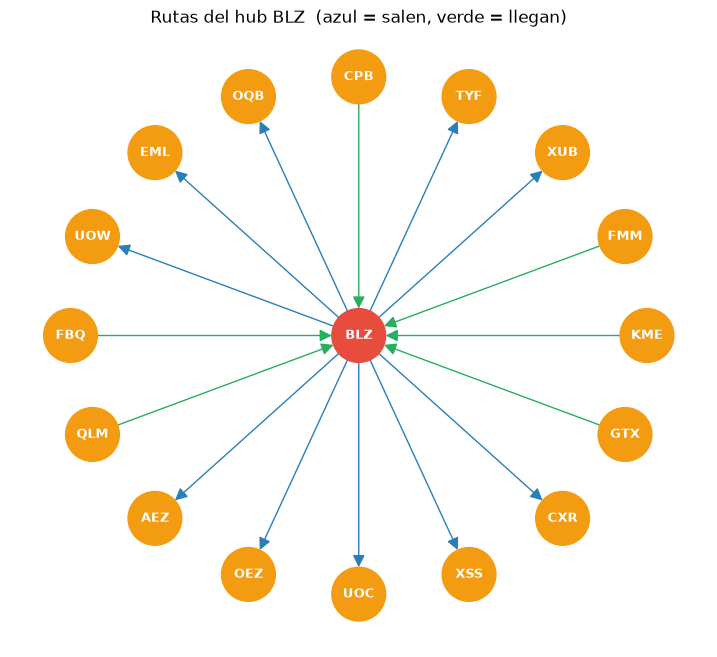

In [12]:
import matplotlib.pyplot as plt

# Aeropuerto con más conexiones (entradas + salidas)
grados = dict(G.degree())
hub = max(grados, key=grados.get)
print(f"Hub principal: {hub} con {grados[hub]} rutas")

# Subgrafo: el hub + sus vecinos directos
sub = nx.ego_graph(G, hub, radius=1, undirected=True)
vecinos = [n for n in sub.nodes() if n != hub]
salidas  = [(u, v) for u, v in sub.edges() if u == hub]
llegadas = [(u, v) for u, v in sub.edges() if v == hub]

plt.figure(figsize=(9, 8))
pos = nx.shell_layout(sub, nlist=[[hub], vecinos])   # hub al centro, vecinos en círculo
colores = ['#E74C3C' if n == hub else '#F39C12' for n in sub.nodes()]

nx.draw_networkx_nodes(sub, pos, node_color=colores, node_size=1500)
nx.draw_networkx_labels(sub, pos, font_size=9, font_weight='bold', font_color='white')
nx.draw_networkx_edges(sub, pos, edgelist=salidas,  edge_color='#2980B9', arrowsize=18, node_size=1500)
nx.draw_networkx_edges(sub, pos, edgelist=llegadas, edge_color='#27AE60', arrowsize=18, node_size=1500)

plt.title(f'Rutas del hub {hub}  (azul = salen, verde = llegan)')
plt.axis('off')
plt.show()